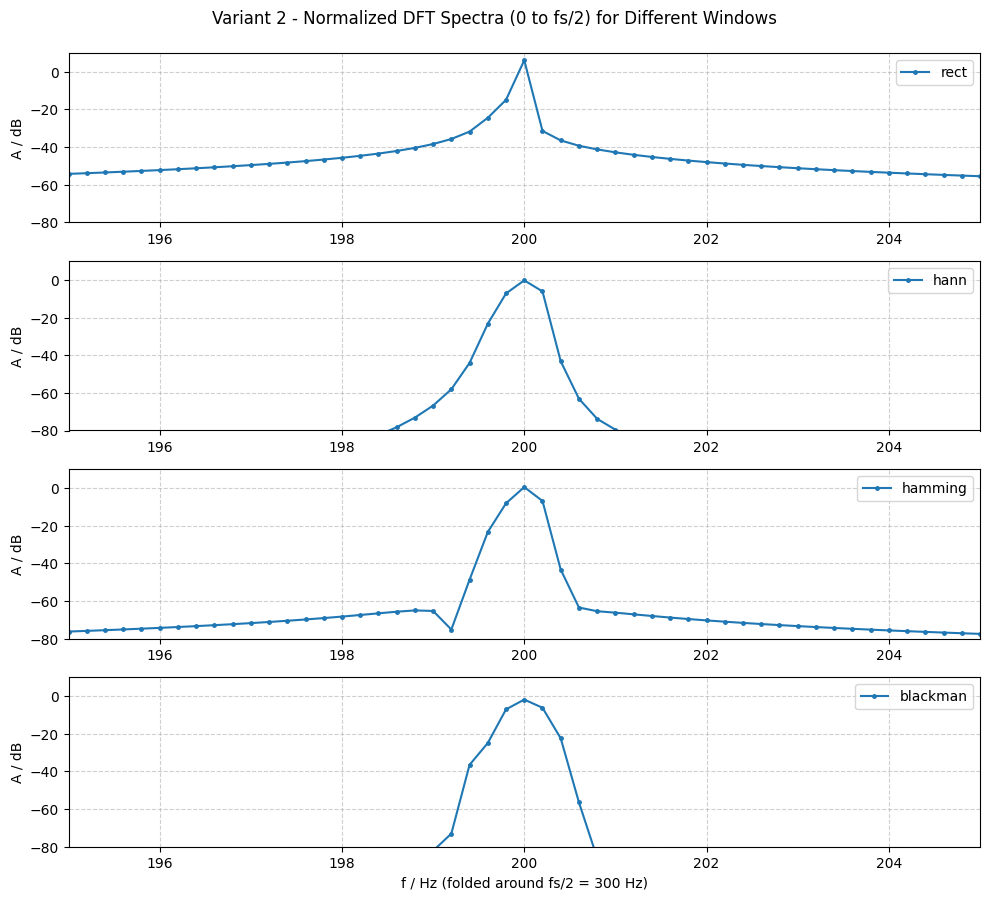

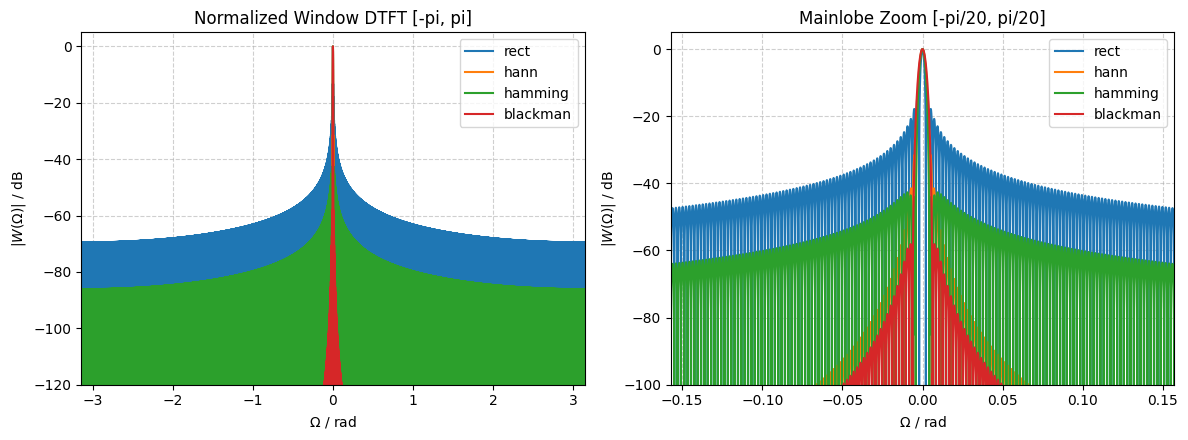

In [2]:
import warnings

warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
from numpy.fft import fft, fftshift
from scipy.signal.windows import blackman, hamming, hann

# Variant 2 parameters from Table 1
f1 = 400.0  # Hz
f2 = 400.25  # Hz
f3 = 399.75  # Hz
fs = 600.0  # Hz
N = 3000  # number of samples

A1 = 2.0  # |x[k]|_max
A2 = 0.1 * A1  # 0.2
A3 = 0.01 * A1  # 0.02

# Time index and three-tone discrete-time signal
k = np.arange(N)
x = (
    A1 * np.sin(2 * np.pi * f1 / fs * k)
    + A2 * np.sin(2 * np.pi * f2 / fs * k)
    + A3 * np.sin(2 * np.pi * f3 / fs * k)
)

# Periodic windows (sym=False for spectral analysis)
windows = {
    'rect': np.ones(N),
    'hann': hann(N, sym=False),
    'hamming': hamming(N, sym=False),
    'blackman': blackman(N, sym=False),
}


def fft2db(X):
  """Normalized DFT magnitude in dB for sine-wave amplitude scaling."""
  M = X.size
  Xtmp = (2.0 / M) * X
  Xtmp[0] *= 0.5  # DC bin (0 Hz) appears once
  if M % 2 == 0:
    Xtmp[M // 2] *= 0.5  # Nyquist bin (fs/2) appears once
  return 20.0 * np.log10(np.abs(Xtmp) + 1e-15)


def win_dtft_db(w, pad_factor=50):
  """Normalized window DTFT spectrum in dB over [-pi, pi]."""
  M = len(w)
  Nz = pad_factor * M
  W_pad = np.zeros(Nz)
  W_pad[:M] = w
  W_mag = np.abs(fftshift(fft(W_pad)))
  W_mag /= np.max(W_mag) + 1e-15
  W_db = 20.0 * np.log10(W_mag + 1e-15)
  Omega = 2.0 * np.pi / Nz * np.arange(Nz) - np.pi
  return Omega, W_db


# Frequency axis for DFT (0 to fs/2)
df = fs / N
f = np.arange(N) * df
half_N = N // 2 + 1

# 1. Plot normalized DFT spectra in [0, fs/2] around folded tones (195-205 Hz)
plt.figure(figsize=(10, 9))
for idx, (name, w) in enumerate(windows.items(), start=1):
  X_w = fft(x * w)
  plt.subplot(len(windows), 1, idx)
  plt.plot(f[:half_N], fft2db(X_w)[:half_N], 'o-', ms=2.5, label=name)
  plt.xlim(195, 205)
  plt.ylim(-80, 10)
  plt.ylabel('A / dB')
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.6)
  if idx == len(windows):
    plt.xlabel('f / Hz (folded around fs/2 = 300 Hz)')

plt.suptitle(
    'Variant 2 - Normalized DFT Spectra (0 to fs/2) for Different Windows',
    y=0.995,
)
plt.tight_layout()
plt.savefig('dft_spectra_windows.png', dpi=200)
plt.show()

# 2. Plot normalized window DTFT spectra over [-pi, pi] and mainlobe zoom
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name, w in windows.items():
  Omega, W_db = win_dtft_db(w, pad_factor=50)
  axes[0].plot(Omega, W_db, label=name)
  axes[1].plot(Omega, W_db, label=name)

axes[0].set_title('Normalized Window DTFT [-pi, pi]')
axes[0].set_xlim(-np.pi, np.pi)
axes[0].set_ylim(-120, 5)
axes[0].set_xlabel(r'$\Omega$ / rad')
axes[0].set_ylabel(r'$|W(\Omega)|$ / dB')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

axes[1].set_title('Mainlobe Zoom [-pi/20, pi/20]')
axes[1].set_xlim(-np.pi / 20, np.pi / 20)
axes[1].set_ylim(-100, 5)
axes[1].set_xlabel(r'$\Omega$ / rad')
axes[1].set_ylabel(r'$|W(\Omega)|$ / dB')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.savefig('window_dtft_spectra.png', dpi=200)
plt.show()